In [5]:
import os
os.chdir(os.path.expanduser("~/github/DATASCI266-Banking77-Encoder-vs-Decoder"))

In [6]:
import pandas as pd
import numpy as np
import glob
import json

labels = json.load(open("data/raw/label_names.json"))

In [10]:
files = sorted(glob.glob("results/qwen_qlora_*.csv"))
print(f'Found {len(files)} files')

Found 42 files


In [ ]:
#check the results file:
sample = pd.read_csv(files[0])
print(sample.head(2))
print(f'\nColumns: {list(sample.columns)}')
print(f'\n Rows: {len(sample)}')

        model     type budget  seed split  example_id  true_label  \
0  qwen_qlora  decoder    k10     0  test           0          11   
1  qwen_qlora  decoder    k10     0  test           1          11   

   predicted_label         raw_output  
0               38  get_physical_card  
1               11       card_arrival  

Columns: ['model', 'type', 'budget', 'seed', 'split', 'example_id', 'true_label', 'predicted_label', 'raw_output']

 Rows: 3080


In [28]:
# for the analysis table, need to extract cols with names 'budget', 'seed', 'split'

#check the file name:
print(files[0])

name = files[0].split('/')[-1].replace('.csv', '')
parts = name.split('_')
print(parts)

budget = parts[2]
seed = int(parts[3].replace('seed', ''))
split = parts[4]                         # 'test'
print(f"Budget: {budget}, Seed: {seed}, Split: {split}")


results/qwen_qlora_k10_seed0_test.csv
['qwen', 'qlora', 'k10', 'seed0', 'test']
Budget: k10, Seed: 0, Split: test


In [29]:
# accuracy = how many predictions matched the true label
df = pd.read_csv(files[0])

correct = df["predicted_label"] == df["true_label"]  # True/False for each row
accuracy = correct.mean()                             # fraction that are True

print(f"Correct: {correct.sum()} out of {len(df)}")
print(f"Accuracy: {accuracy:.3f}")

Correct: 1816 out of 3080
Accuracy: 0.590


In [30]:
# same logic as above, but for every file
rows = []

for f in sorted(files):
    # parse filename
    name = f.split("/")[-1].replace(".csv", "")
    parts = name.split("_")
    budget = parts[2]
    seed = int(parts[3].replace("seed", ""))
    split = parts[4]
    
    # calculate accuracy
    df = pd.read_csv(f)
    acc = (df["predicted_label"] == df["true_label"]).mean()
    
    # store it
    rows.append({
        "budget": budget,
        "seed": seed,
        "split": split,
        "accuracy": round(acc, 3),
    })

results = pd.DataFrame(rows)
print(f"Total rows: {len(results)}")
print(results.head(10))

Total rows: 42
  budget  seed split  accuracy
0    k10     0  test     0.590
1    k10     0   val     0.587
2    k10     1  test     0.624
3    k10     1   val     0.595
4    k10     2  test     0.646
5    k10     2   val     0.634
6     k1     0  test     0.467
7     k1     0   val     0.416
8     k1     1  test     0.465
9     k1     1   val     0.408


In [31]:
# group by budget and split, take the mean of the 3 seeds
summary = (results
    .groupby(["budget", "split"])["accuracy"]
    .mean()
    .unstack("split")  # puts val and test as columns side by side
    .reindex(["k1", "k3", "k5", "k10", "k20", "k30", "p50"])  # order by size
)

# add the difference column
summary["delta"] = summary["test"] - summary["val"]
summary = summary.round(3)

print("Qwen SFT: Val vs Test (mean across 3 seeds)")
print("=" * 50)
print(summary)

Qwen SFT: Val vs Test (mean across 3 seeds)
split    test    val  delta
budget                     
k1      0.463  0.412  0.051
k3      0.496  0.436  0.061
k5      0.530  0.493  0.037
k10     0.620  0.605  0.015
k20     0.720  0.711  0.010
k30     0.762  0.743  0.019
p50     0.779  0.777  0.002


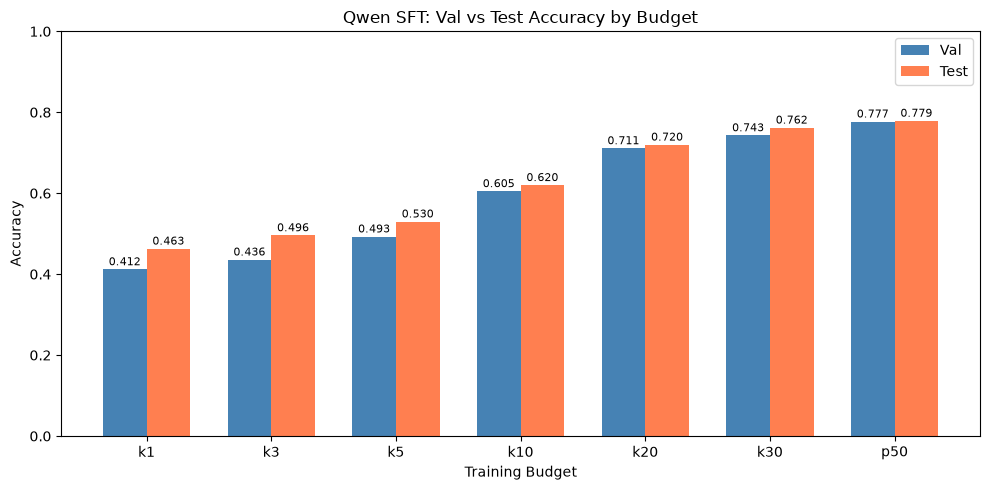

In [32]:
import matplotlib.pyplot as plt

budgets = ["k1", "k3", "k5", "k10", "k20", "k30", "p50"]
val_means = summary["val"].values
test_means = summary["test"].values

x = range(len(budgets))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar([i - width/2 for i in x], val_means, width, label="Val", color="steelblue")
ax.bar([i + width/2 for i in x], test_means, width, label="Test", color="coral")

ax.set_xlabel("Training Budget")
ax.set_ylabel("Accuracy")
ax.set_title("Qwen SFT: Val vs Test Accuracy by Budget")
ax.set_xticks(x)
ax.set_xticklabels(budgets)
ax.set_ylim(0, 1.0)
ax.legend()

# add accuracy values on top of each bar
for i in x:
    ax.text(i - width/2, val_means[i] + 0.01, f"{val_means[i]:.3f}", ha="center", fontsize=8)
    ax.text(i + width/2, test_means[i] + 0.01, f"{test_means[i]:.3f}", ha="center", fontsize=8)

plt.tight_layout()
plt.show()